# Análise Exploratória dos Logs de Pavimento e Vibração

Este notebook realiza a varredura automática, consolidação estatística e análise gráfica dos dados coletados pelo aplicativo Android de monitoramento da qualidade do pavimento.

- **Diretório dos dados**: `concerns/logs/`
- **Métricas avaliadas**: Quantidade de amostras, duração total, frequência média de amostragem ($Hz$), estatísticas de aceleração vertical ($Z$), dados de GPS/velocidade e detecção de anomalias.

In [1]:
# Configuração do ambiente e importações
import os
import re
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.autolayout"] = True
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print("✓ Ambiente configurado e bibliotecas importadas!")

✓ Ambiente configurado e bibliotecas importadas!


---
## 1. Função para Varrer os Logs e Extrair Informações

A função `scan_logs` inspeciona todos os arquivos `.csv` na pasta `logs/` (ou caminho informado), tratando arquivos vazios e diferentes esquemas de sensores coletados pelo app.

In [2]:
def parse_datetime_from_filename(filename: str):
    """Extrai datetime a partir do nome do arquivo no padrão AAAAMMDD_HHMMSS."""
    match = re.search(r"(\d{8})_(\d{6})", filename)
    if match:
        date_part, time_part = match.groups()
        try:
            return datetime.strptime(f"{date_part}_{time_part}", "%Y%m%d_%H%M%S")
        except ValueError:
            return None
    return None

def format_bytes(size_bytes: int) -> str:
    """Converte bytes para formato legível (B, KB, MB)."""
    if size_bytes < 1024:
        return f"{size_bytes} B"
    elif size_bytes < 1024 * 1024:
        return f"{size_bytes / 1024:.1f} KB"
    return f"{size_bytes / (1024 * 1024):.2f} MB"

def format_duration(seconds: float) -> str:
    """Converte segundos em MM:SS ou HH:MM:SS."""
    if seconds <= 0:
        return "00:00"
    total_sec = int(round(seconds))
    hours = total_sec // 3600
    minutes = (total_sec % 3600) // 60
    sec = total_sec % 60
    if hours > 0:
        return f"{hours:02d}:{minutes:02d}:{sec:02d}"
    return f"{minutes:02d}:{sec:02d}"

def load_log(filepath: str | Path) -> pd.DataFrame:
    """Carrega um arquivo CSV, padroniza nomes de colunas e trata linhas incompletas."""
    path = Path(filepath)
    if not path.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {path}")
    df = pd.read_csv(path)
    if df.empty:
        return pd.DataFrame()

    norm = pd.DataFrame()
    # Identificar coluna de timestamp
    if "timestampMs" in df.columns:
        norm["timestamp_ms"] = pd.to_numeric(df["timestampMs"], errors="coerce")
    elif "timestamp" in df.columns:
        norm["timestamp_ms"] = pd.to_numeric(df["timestamp"], errors="coerce")
    else:
        norm["timestamp_ms"] = np.arange(len(df))

    norm = norm.dropna(subset=["timestamp_ms"])
    if norm.empty:
        return pd.DataFrame()

    # Tratar eventuais truncamentos de escrita no último registro
    t0 = norm["timestamp_ms"].iloc[0]
    norm = norm[norm["timestamp_ms"] >= t0].copy()
    norm["elapsed_sec"] = (norm["timestamp_ms"] - t0) / 1000.0

    # Aceleração vertical Z
    if "z_accel" in df.columns:
        norm["z_accel"] = pd.to_numeric(df["z_accel"], errors="coerce")
    elif "zAcceleration" in df.columns:
        norm["z_accel"] = pd.to_numeric(df["zAcceleration"], errors="coerce")
    else:
        norm["z_accel"] = np.nan

    # Acurácia
    norm["accuracy"] = df.get("accuracy", df.get("zAccuracy", 3))

    # Anomalias
    norm["is_anomaly"] = df["isAnomaly"].astype(bool) if "isAnomaly" in df.columns else False

    # GPS e Velocidade
    lat_c = "lat" if "lat" in df.columns else ("latitude" if "latitude" in df.columns else None)
    lon_c = "lon" if "lon" in df.columns else ("longitude" if "longitude" in df.columns else None)
    spd_c = "speed" if "speed" in df.columns else ("speedMetersPerSecond" if "speedMetersPerSecond" in df.columns else None)

    norm["lat"] = pd.to_numeric(df[lat_c], errors="coerce") if lat_c else np.nan
    norm["lon"] = pd.to_numeric(df[lon_c], errors="coerce") if lon_c else np.nan
    norm["speed_kmh"] = pd.to_numeric(df[spd_c], errors="coerce") * 3.6 if spd_c else np.nan

    return norm

def scan_logs(target_dir: str | Path = "logs") -> pd.DataFrame:
    """Varre o diretório e calcula métricas completas de cada log."""
    dir_path = Path(target_dir)
    if not dir_path.exists():
        if Path("concerns/logs").exists():
            dir_path = Path("concerns/logs")
        elif Path("logs").exists():
            dir_path = Path("logs")
        else:
            dir_path = Path(".")

    files = sorted(dir_path.glob("*.csv"))
    records = []

    for f in files:
        size_bytes = f.stat().st_size
        dt = parse_datetime_from_filename(f.name)
        dt_str = dt.strftime("%Y-%m-%d %H:%M:%S") if dt else "N/A"

        try:
            df = load_log(f)
            total_samples = len(df)
        except Exception as e:
            records.append({
                "Arquivo": f.name,
                "Status": f"Erro: {e}",
                "Qtd Amostras": 0,
                "Tamanho": format_bytes(size_bytes),
                "Data/Hora": dt_str,
                "Duração": "00:00",
                "Duração (s)": 0.0,
                "Freq (Hz)": 0.0,
                "Z Médio (m/s²)": np.nan,
                "Z DesvPad": np.nan,
                "Z Mín": np.nan,
                "Z Máx": np.nan,
                "GPS Válidos": 0,
                "Vel Média (km/h)": np.nan,
                "Vel Máx (km/h)": np.nan,
                "Anomalias": 0,
                "Path": str(f)
            })
            continue

        if total_samples == 0:
            records.append({
                "Arquivo": f.name,
                "Status": "Vazio (Sem dados)",
                "Qtd Amostras": 0,
                "Tamanho": format_bytes(size_bytes),
                "Data/Hora": dt_str,
                "Duração": "00:00",
                "Duração (s)": 0.0,
                "Freq (Hz)": 0.0,
                "Z Médio (m/s²)": np.nan,
                "Z DesvPad": np.nan,
                "Z Mín": np.nan,
                "Z Máx": np.nan,
                "GPS Válidos": 0,
                "Vel Média (km/h)": np.nan,
                "Vel Máx (km/h)": np.nan,
                "Anomalias": 0,
                "Path": str(f)
            })
        else:
            dur_s = df["elapsed_sec"].iloc[-1] - df["elapsed_sec"].iloc[0]
            freq = (total_samples - 1) / dur_s if dur_s > 0 else 0.0
            z = df["z_accel"].dropna()
            spd = df["speed_kmh"].dropna()
            spd_valid = spd[spd >= 0]
            gps_valid = df[df["lat"].notna() & (df["lat"] != 0)]

            records.append({
                "Arquivo": f.name,
                "Status": "Com dados",
                "Qtd Amostras": total_samples,
                "Tamanho": format_bytes(size_bytes),
                "Data/Hora": dt_str,
                "Duração": format_duration(dur_s),
                "Duração (s)": round(dur_s, 2),
                "Freq (Hz)": round(freq, 1),
                "Z Médio (m/s²)": round(z.mean(), 3) if not z.empty else np.nan,
                "Z DesvPad": round(z.std(), 3) if not z.empty else np.nan,
                "Z Mín": round(z.min(), 3) if not z.empty else np.nan,
                "Z Máx": round(z.max(), 3) if not z.empty else np.nan,
                "GPS Válidos": len(gps_valid),
                "Vel Média (km/h)": round(spd_valid.mean(), 1) if not spd_valid.empty else np.nan,
                "Vel Máx (km/h)": round(spd_valid.max(), 1) if not spd_valid.empty else np.nan,
                "Anomalias": int(df["is_anomaly"].sum()),
                "Path": str(f)
            })
    return pd.DataFrame(records)

print("✓ Funções scan_logs e load_log definidas com sucesso!")

✓ Funções scan_logs e load_log definidas com sucesso!


---
## 2. Tabela Resumo dos Logs

Execução da varredura na pasta de logs. A tabela apresenta cada arquivo com suas respectivas métricas.

In [3]:
# Executar varredura
summary_df = scan_logs("logs")

# Adicionar coluna de número (1 a N) para facilitar a seleção nos blocos abaixo
if "Nº" not in summary_df.columns:
    summary_df.insert(0, "Nº", range(1, len(summary_df) + 1))

# Métricas globais
total_files = len(summary_df)
active_files = len(summary_df[summary_df["Qtd Amostras"] > 0])
total_samples = summary_df["Qtd Amostras"].sum()
total_seconds = summary_df["Duração (s)"].sum()

print(f"=======================================================")
print(f"📊 PAINEL GERAL DE MONITORAMENTO DE PAVIMENTO")
print(f"=======================================================")
print(f"• Total de arquivos de log:           {total_files}")
print(f"• Arquivos com medições válidas:     {active_files} (vazios/apenas cabeçalho: {total_files - active_files})")
print(f"• Total acumulado de amostras:        {total_samples:,}")
print(f"• Tempo total acumulado de corrida:   {format_duration(total_seconds)} ({total_seconds/60:.1f} minutos)")
print(f"=======================================================\n")

# Colunas para visualização na tabela (incluindo Nº para seleção direta)
cols_to_show = [
    "Nº", "Arquivo", "Status", "Qtd Amostras", "Duração", "Freq (Hz)",
    "Z Médio (m/s²)", "Z DesvPad", "Z Mín", "Z Máx",
    "GPS Válidos", "Vel Média (km/h)", "Tamanho", "Data/Hora"
]

# Exibir tabela completa
summary_df[cols_to_show]


📊 PAINEL GERAL DE MONITORAMENTO DE PAVIMENTO
• Total de arquivos de log:           11
• Arquivos com medições válidas:     11 (vazios/apenas cabeçalho: 0)
• Total acumulado de amostras:        359,084
• Tempo total acumulado de corrida:   01:25:42 (85.7 minutos)



,Arquivo,Status,Qtd Amostras,Duração,Freq (Hz),Z Médio (m/s²),Z DesvPad,Z Mín,Z Máx,GPS Válidos,Vel Média (km/h),Tamanho,Data/Hora
0,pavement_log_20261024_121748.csv,Com dados,20799,06:58,49.7,0.084,1.180,-21.747,16.843,20799,24.2,1.53 MB,2026-10-24 12:17:48
1,pavement_log_20261024_125006.csv,Com dados,26787,08:59,49.7,0.019,0.975,-12.118,29.759,26787,21.8,1.97 MB,2026-10-24 12:50:06
2,pavement_log_20261024_165517.csv,Com dados,58673,26:55,36.3,0.069,1.152,-15.669,17.305,58673,16.7,4.28 MB,2026-10-24 16:55:17
3,pavement_log_20261030_174730.csv,Com dados,17320,02:53,100.3,0.197,1.616,-8.198,22.897,17320,97.5,1.28 MB,2026-10-30 17:47:30
4,pavement_log_20261030_184817.csv,Com dados,3599,00:36,99.2,0.197,1.815,-16.087,21.552,3599,88.3,272.0 KB,2026-10-30 18:48:17
5,pavement_log_20261030_185457.csv,Com dados,3138,00:32,99.2,0.082,0.742,-6.664,6.591,3138,98.6,240.0 KB,2026-10-30 18:54:57
6,pavement_log_20261030_185801.csv,Com dados,57032,09:34,99.3,0.070,0.659,-7.629,10.704,57032,83.7,4.23 MB,2026-10-30 18:58:01
7,pavement_log_20261030_190737.csv,Com dados,36658,06:29,94.2,0.086,0.562,-4.221,5.253,36658,83.2,2.73 MB,2026-10-30 19:07:37
8,pavement_log_20261030_191408.csv,Com dados,25556,04:23,97.1,0.070,0.751,-3.572,5.356,25556,101.1,1.90 MB,2026-10-30 19:14:08
9,pavement_log_20261030_191832.csv,Com dados,67552,11:20,99.3,0.056,0.633,-4.042,4.859,67552,79.7,5.01 MB,2026-10-30 19:18:32


---
## 3. Visualização Gráfica de Todos os Logs (Séries Temporais)

Neste bloco, plotamos as séries temporais de aceleração vertical ($Z$) de **todos os logs que possuem amostras coletadas**.
- Linha tracejada em zero representa a linha de base.
- Pontos vermelhos indicam anomalias sinalizadas pelo algoritmo.

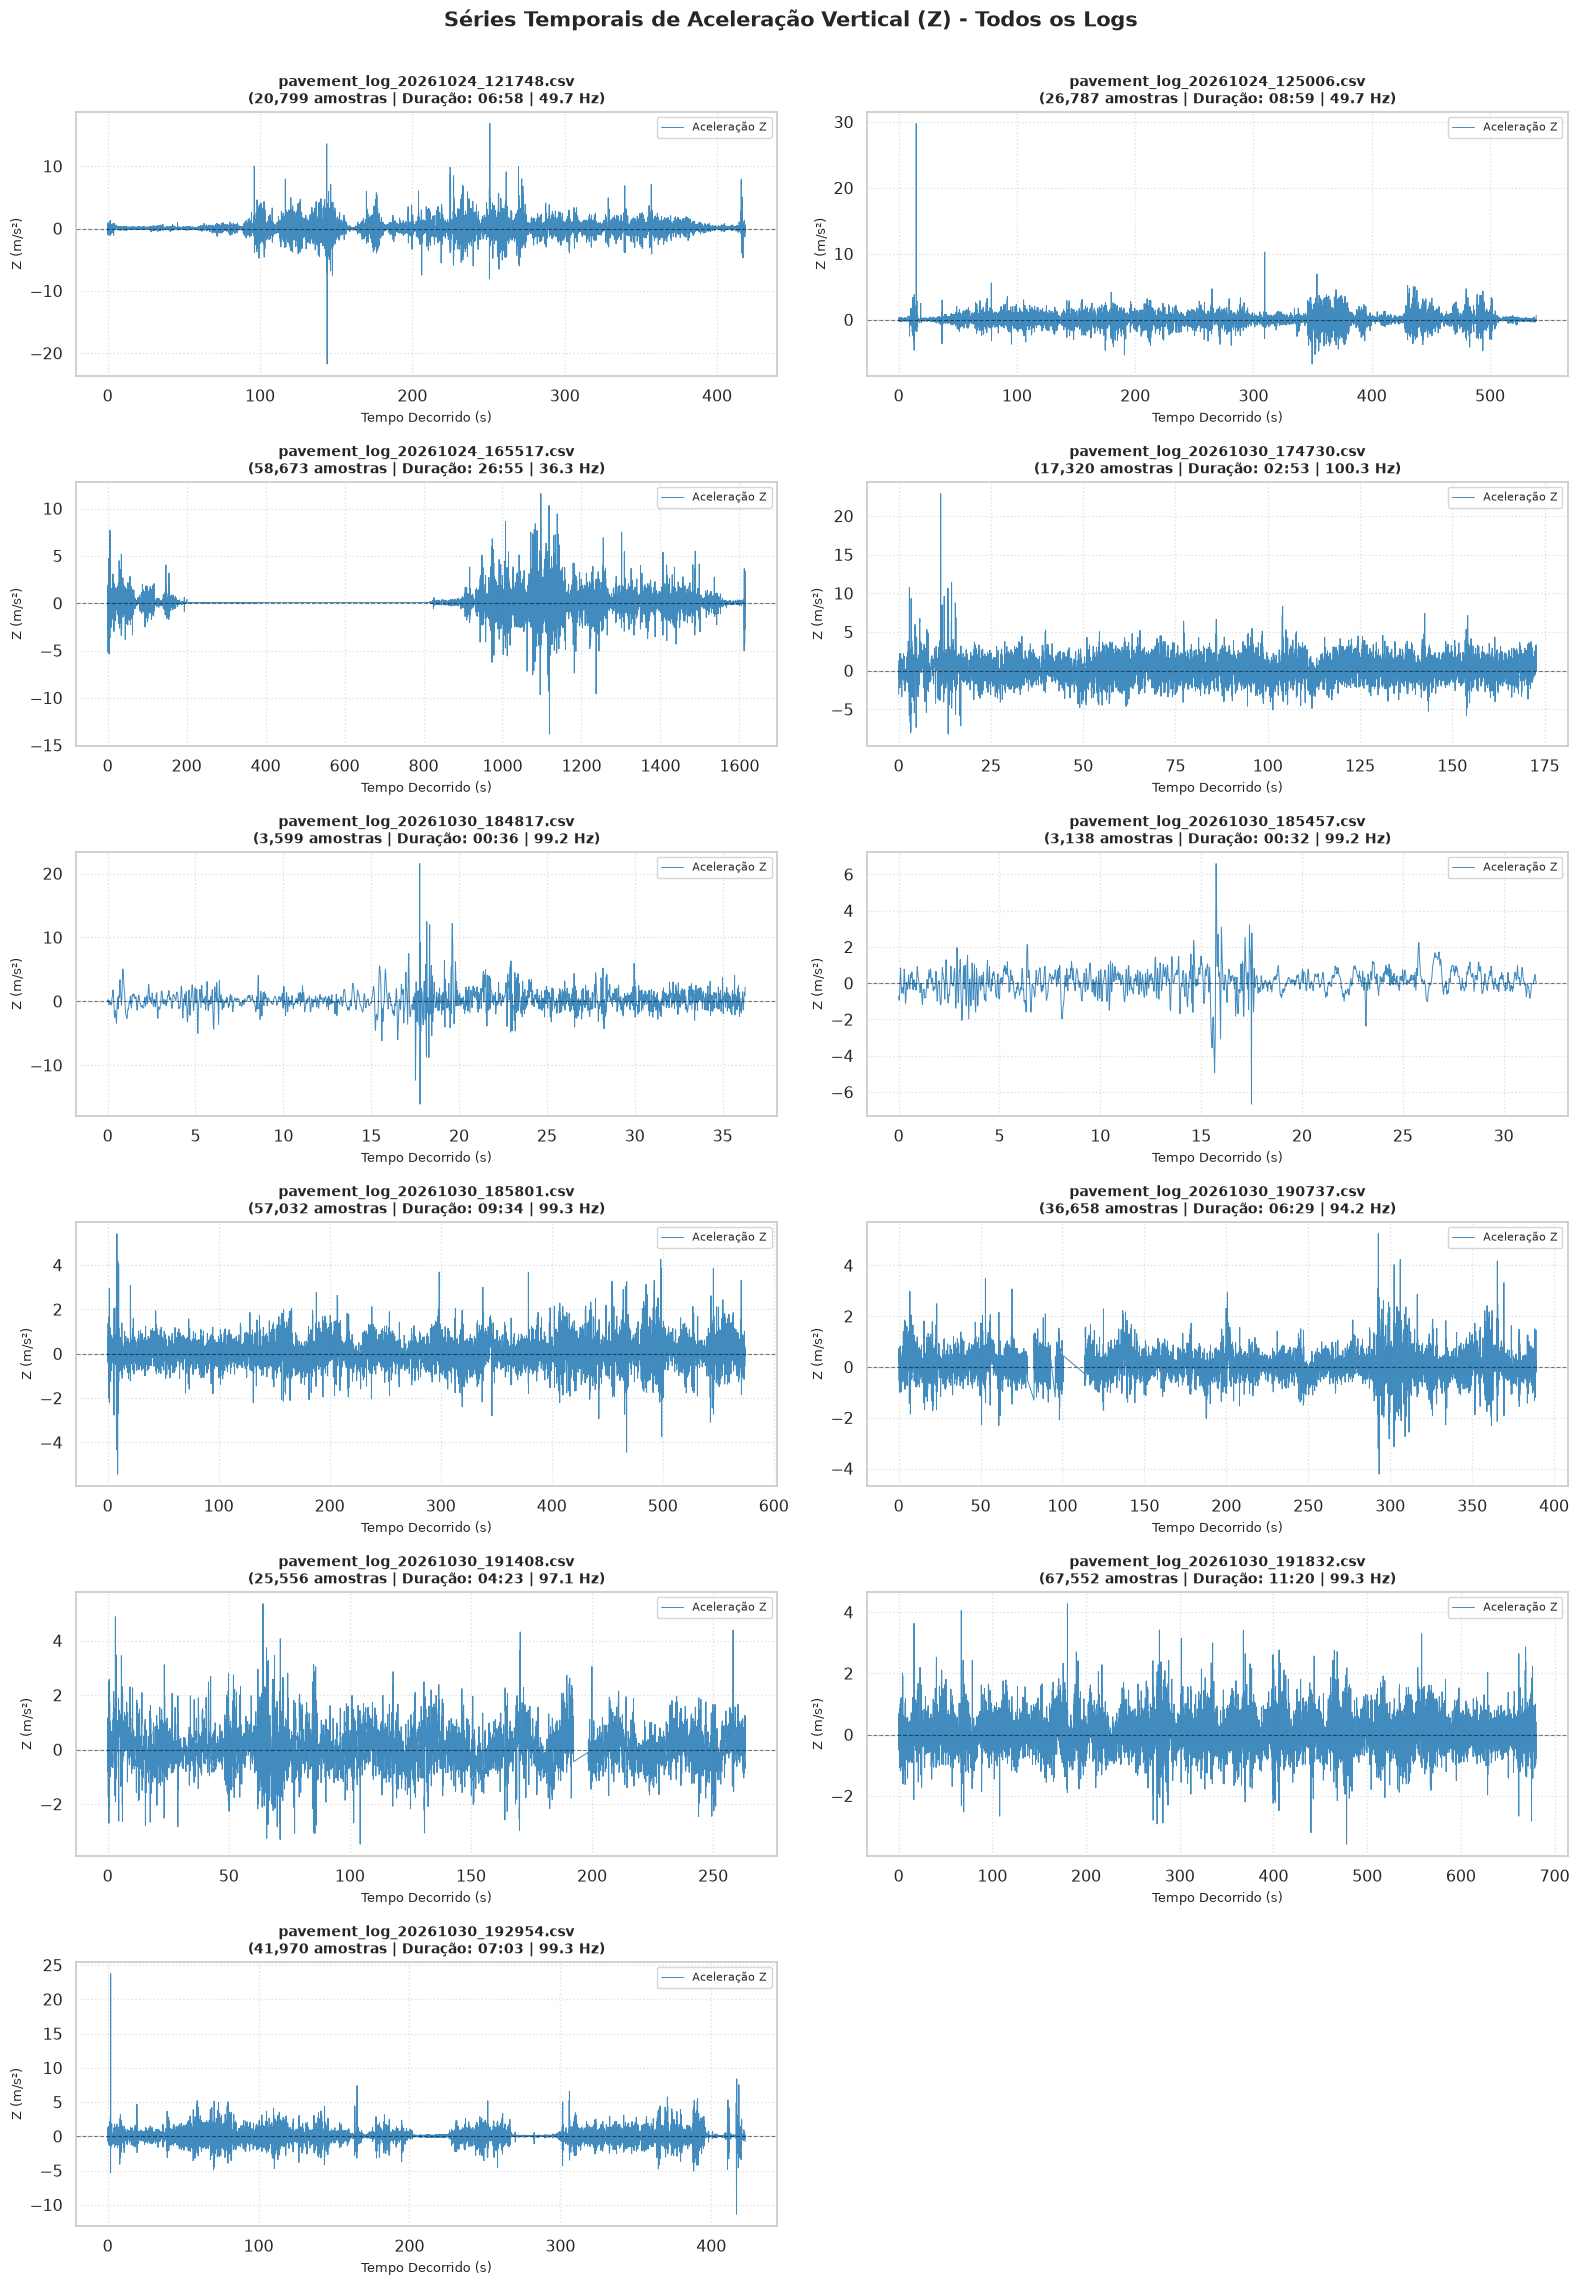

In [4]:
active_logs = summary_df[summary_df["Qtd Amostras"] > 0].reset_index(drop=True)
n_plots = len(active_logs)
n_cols = 2
n_rows = (n_plots + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.8 * n_rows), sharex=False)
axes_flat = axes.flatten()

for idx, row in active_logs.iterrows():
    ax = axes_flat[idx]
    df = load_log(row["Path"])
    
    # Otimização visual para logs com dezenas de milhares de amostras
    if len(df) > 8000:
        step = max(1, len(df) // 8000)
        plot_df = df.iloc[::step]
    else:
        plot_df = df
        
    ax.plot(plot_df["elapsed_sec"], plot_df["z_accel"], color="#1f77b4", linewidth=0.7, alpha=0.85, label="Aceleração Z")
    ax.axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.5)
    
    # Anomalias
    if "is_anomaly" in df.columns and df["is_anomaly"].any():
        anom = df[df["is_anomaly"]]
        ax.scatter(anom["elapsed_sec"], anom["z_accel"], color="red", s=25, label="Anomalia", zorder=5)
        
    title_str = f"{row['Arquivo']}\n({row['Qtd Amostras']:,} amostras | Duração: {row['Duração']} | {row['Freq (Hz)']} Hz)"
    ax.set_title(title_str, fontsize=10, fontweight="bold")
    ax.set_xlabel("Tempo Decorrido (s)", fontsize=9)
    ax.set_ylabel("Z (m/s²)", fontsize=9)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper right", fontsize=8)

# Ocultar eixos vazios na grade
for j in range(n_plots, len(axes_flat)):
    axes_flat[j].set_visible(False)

plt.suptitle("Séries Temporais de Aceleração Vertical (Z) - Todos os Logs", fontsize=15, fontweight="bold", y=1.002)
plt.tight_layout()
plt.show()

---
## 4. Comparativo de Amostras, Duração e Intensidade de Vibração

Comparações entre todas as corridas ativas:
1. **Volume de dados**: Quantidade de amostras por arquivo.
2. **Duração**: Tempo total de monitoramento por sessão.
3. **Rugosidade / Vibração**: Desvio padrão de $Z$ (quanto maior, mais irregular o trecho de pavimento).

/tmp/ipykernel_80496/275238548.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=active_logs, x="Qtd Amostras", y="Arquivo", ax=ax1, palette="Blues_r")
/tmp/ipykernel_80496/275238548.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=active_logs, x="Duração (s)", y="Arquivo", ax=ax2, palette="Greens_r")


/tmp/ipykernel_80496/275238548.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=active_logs, x="Z DesvPad", y="Arquivo", ax=ax3, palette="Oranges_r")


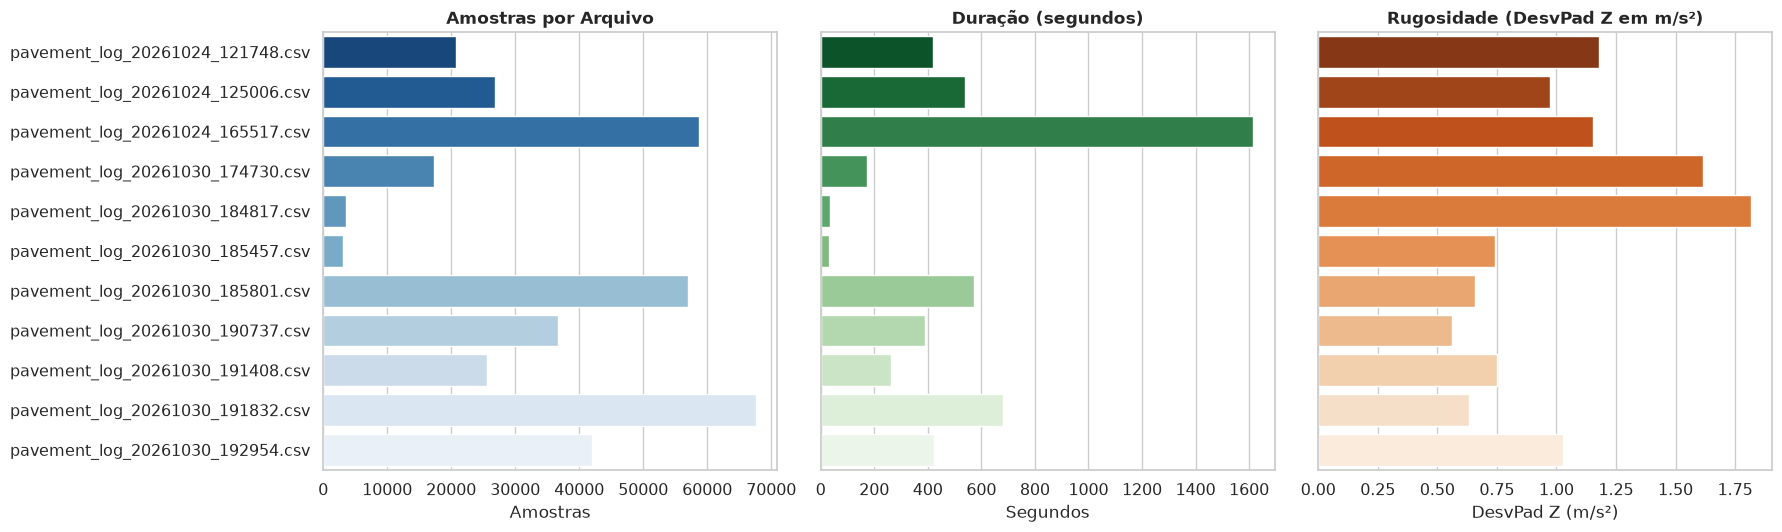

In [5]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Qtd Amostras
sns.barplot(data=active_logs, x="Qtd Amostras", y="Arquivo", ax=ax1, palette="Blues_r")
ax1.set_title("Amostras por Arquivo", fontweight="bold")
ax1.set_xlabel("Amostras")
ax1.set_ylabel("")

# 2. Duração
sns.barplot(data=active_logs, x="Duração (s)", y="Arquivo", ax=ax2, palette="Greens_r")
ax2.set_title("Duração (segundos)", fontweight="bold")
ax2.set_xlabel("Segundos")
ax2.set_ylabel("")
ax2.set_yticklabels([])

# 3. Rugosidade (Desvio Padrão Z)
sns.barplot(data=active_logs, x="Z DesvPad", y="Arquivo", ax=ax3, palette="Oranges_r")
ax3.set_title("Rugosidade (DesvPad Z em m/s²)", fontweight="bold")
ax3.set_xlabel("DesvPad Z (m/s²)")
ax3.set_ylabel("")
ax3.set_yticklabels([])

plt.tight_layout()
plt.show()

---
## 5. Inspeção Detalhada: Aceleração Z vs Velocidade Veicular (GPS)

Análise aprofundada correlacionando aceleração vertical e velocidade para o log escolhido.  
**Basta alterar o valor da variável `NUMERO_LOG` na célula abaixo e executar o bloco (`Shift + Enter`).**


Exibindo detalhes para o log com maior amostragem GPS: pavement_log_20261030_191832.csv


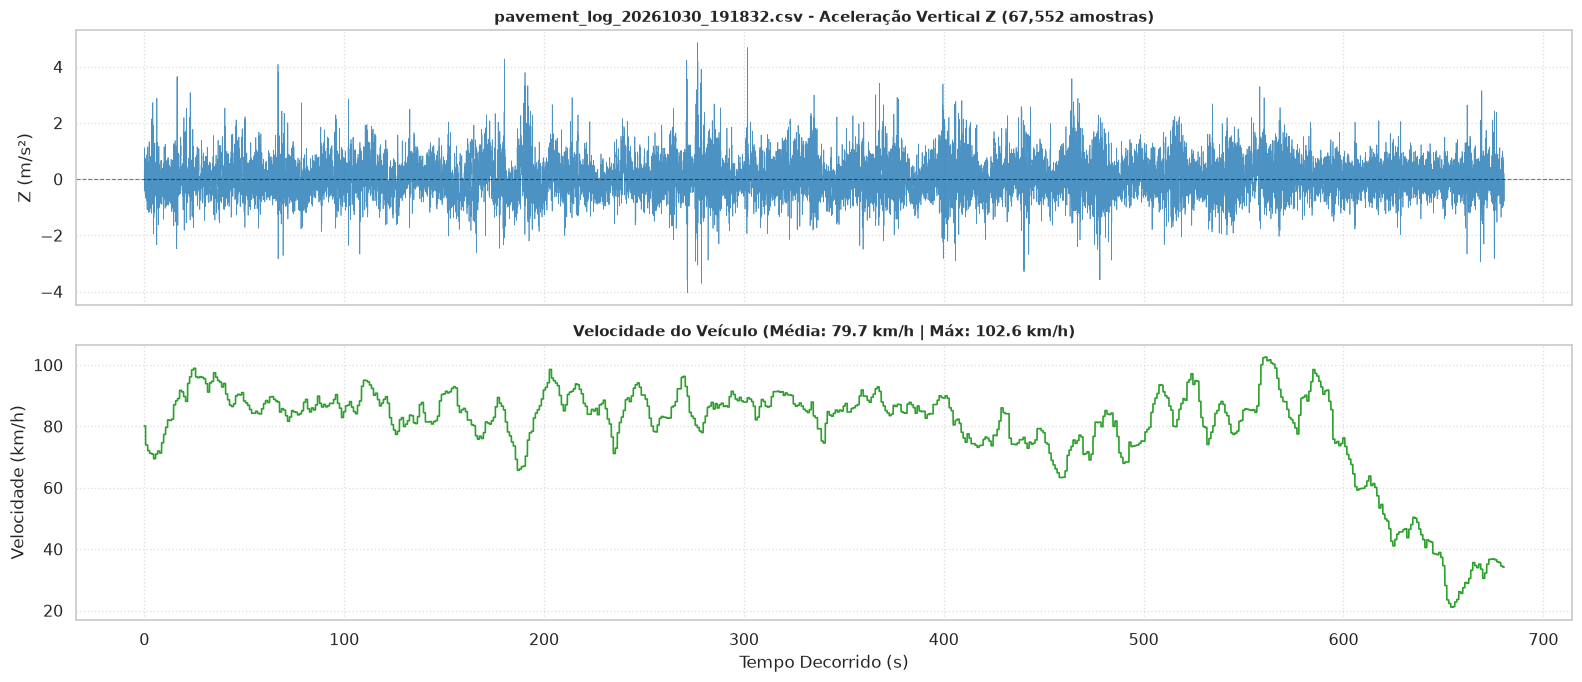

In [6]:
# ==============================================================================
# SELEÇÃO DO LOG PARA INSPEÇÃO DETALHADA
# Digite o número do log desejado (1 a 11) ou índice (0 a 10):
# ==============================================================================
NUMERO_LOG = 2  # <--- DIGITE O NÚMERO DO LOG AQUI E RODE O BLOCO (Shift + Enter)!
# ==============================================================================

# Validação e mapeamento do índice
if 1 <= NUMERO_LOG <= len(active_logs):
    target_idx = NUMERO_LOG - 1
else:
    target_idx = max(0, min(int(NUMERO_LOG), len(active_logs) - 1))

target = active_logs.iloc[target_idx]
print(f"==============================================================================")
print(f"📍 LOG SELECIONADO: [Nº {target_idx + 1}] — {target['Arquivo']}")
print(f"• Amostras: {target['Qtd Amostras']:,} | Duração: {target['Duração']} | Frequência: {target['Freq (Hz)']} Hz")
print(f"• Aceleração Z: Média = {target['Z Médio (m/s²)']} m/s² | Máx = {target['Z Máx']} m/s² | DesvPad = {target['Z DesvPad']} m/s²")
print(f"• GPS: {target['GPS Válidos']:,} fixes válidos | Vel Média = {target['Vel Média (km/h)']} km/h | Vel Máx = {target['Vel Máx (km/h)']} km/h")
print(f"==============================================================================")

df_target = load_log(target["Path"])

fig, (ax_acc, ax_spd) = plt.subplots(2, 1, figsize=(16, 7), sharex=True)

# Série temporal de aceleração Z
ax_acc.plot(df_target["elapsed_sec"], df_target["z_accel"], color="#1f77b4", linewidth=0.6, alpha=0.85)
ax_acc.axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.5)
ax_acc.set_title(f"Log [Nº {target_idx + 1}] {target['Arquivo']} — Aceleração Vertical Z ({target['Qtd Amostras']:,} amostras)", fontsize=11, fontweight="bold")
ax_acc.set_ylabel("Aceleração Z (m/s²)", fontsize=10)
ax_acc.grid(True, linestyle=":", alpha=0.6)

# Velocidade instantânea (GPS)
if target["GPS Válidos"] > 0 and "speed_kmh" in df_target.columns and df_target["speed_kmh"].notna().any():
    ax_spd.plot(df_target["elapsed_sec"], df_target["speed_kmh"], color="#2ca02c", linewidth=1.2)
    ax_spd.set_title(f"Velocidade do Veículo (Média: {target['Vel Média (km/h)']} km/h | Máx: {target['Vel Máx (km/h)']} km/h)", fontsize=11, fontweight="bold")
else:
    ax_spd.text(0.5, 0.5, "Sem dados de velocidade GPS registrados neste log", ha="center", va="center", transform=ax_spd.transAxes, fontsize=12, color="gray")
    ax_spd.set_title("Velocidade do Veículo — Sem Fix GNSS", fontsize=11, fontweight="bold")

ax_spd.set_xlabel("Tempo Decorrido (segundos)", fontsize=10)
ax_spd.set_ylabel("Velocidade (km/h)", fontsize=10)
ax_spd.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


---
## 6. Reconciliação de Dados (MQP) e Detecção de Erro Grosseiro pelo Tempo

A **Capacidade 2** do sistema ciberfísico aplica a técnica de **Reconciliação de Dados por Mínimos Quadrados Ponderados (MQP)** sob restrição física de domínio veicular:

1. **Restrição Física Linear de Domínio:**
   $$f(y) = a_z - k \cdot v = 0 \quad (\text{com } k = 0{,}5\text{ s}^{-1})$$
   Em regime de pavimento regular contínuo (*Quarter-Car Model* / ISO 8608), a excitação vertical da suspensão é proporcional à velocidade horizontal do veículo.

2. **Resíduo Linear e Incerteza Propagada:**
   $$r = y_{az} - k \cdot y_v$$
   $$V_r = \sigma^2_{az} + k^2 \cdot \sigma^2_v$$
   Onde $\sigma^2_{az}$ é obtido dinamicamente da acurácia reportada pelo driver do acelerômetro (`SensorEvent.accuracy`) e $\sigma^2_v$ vem da variância calculada pelo receptor GNSS Doppler (`speedAccuracyMetersPerSecond` ao quadrado).

3. **Teste Global Qui-Quadrado ($\chi^2$):**
   $$\gamma = \frac{r^2}{V_r} \sim \chi^2(1)$$
   - Se $\gamma \le 3{,}84$ ($\alpha = 0{,}05$, nível de confiança de 95% para $\nu = 1$ grau de liberdade): O desvio é mero ruído aleatório dos instrumentos. O MQP calcula as estimativas ótimas reconciliadas $\hat{a}_z$ e $\hat{v}$, sob as quais $\hat{a}_z - k \cdot \hat{v} \equiv 0$.
   - Se $\gamma > 3{,}84$: Ocorre uma **violação física real** da dinâmica de asfalto liso $\implies$ **Erro Grosseiro (`isGrossError = true`)**. O sistema sinaliza o impacto mecânico (buraco/cratera) e preserva o dado bruto contra distorções do estimador.

In [7]:
# ==============================================================================
# FUNÇÃO VETORIZADA DE RECONCILIAÇÃO MQP E TESTE QUI-QUADRADO (CAPACIDADE 2)
# Espelha fielmente a lógica de domínio implementada em Reconciler.kt
# ==============================================================================
def reconcile_series(data: pd.DataFrame, k: float = 0.5, chi_threshold: float = 3.84) -> pd.DataFrame:
    """
    Executa a reconciliação de dados pelo método de Mínimos Quadrados Ponderados (MQP)
    conforme implementado na classe de domínio Reconciler.kt.
    """
    res = data.copy()
    
    # 1. Variáveis observadas (Aceleração vertical em m/s² e velocidade horizontal em m/s)
    res['v_ms'] = (res['speed_kmh'] / 3.6).ffill().bfill().fillna(0.0)
    res['y_az'] = res['z_accel'].fillna(0.0)
    
    # 2. Incertezas dinâmicas dos instrumentos (Variâncias sigma²)
    # Mapeamento do Android SensorEvent.accuracy
    acc_map = {3: 0.25, 2: 1.0, 1: 4.0}
    res['var_az'] = res['accuracy'].map(acc_map).fillna(1.0)
    
    # Variância do receptor GNSS por Doppler
    if 'speed_acc' in res.columns:
        res['var_v'] = (res['speed_acc'].fillna(0.5) ** 2).clip(lower=0.01)
    else:
        res['var_v'] = 0.25
        
    # 3. Resíduo linear do modelo físico: r = az - k * v
    res['r'] = res['y_az'] - (k * res['v_ms'])
    
    # 4. Variância propagada do resíduo: V_r = var_az + k² * var_v
    res['var_r'] = res['var_az'] + (k ** 2) * res['var_v']
    
    # 5. Estatística Qui-Quadrado (Detecção de Erro Grosseiro)
    res['gamma'] = (res['r'] ** 2) / res['var_r']
    res['is_gross_error'] = res['gamma'] > chi_threshold
    
    # 6. Reconciliação ótima MQP (Correção ponderada pela incerteza relativa)
    correction = res['r'] / res['var_r']
    res['reconciled_az'] = res['y_az'] - (res['var_az'] * correction)
    res['reconciled_v_ms'] = res['v_ms'] + (k * res['var_v'] * correction)
    res['reconciled_speed_kmh'] = res['reconciled_v_ms'] * 3.6
    
    # Resíduo pós-reconciliação (deve convergir para zero na precisão de máquina)
    res['post_residual'] = res['reconciled_az'] - (k * res['reconciled_v_ms'])
    
    return res

print("✓ Função reconcile_series definida com sucesso!")

✓ Função reconcile_series definida com sucesso!


### 6.1. Visualização Temporal Completa do MQP pelo Tempo

Abaixo, aplicamos a reconciliação temporal ao log selecionado. Por padrão, ele usa o mesmo `NUMERO_LOG` definido acima, mas você também pode selecionar qualquer outro log diretamente na variável `LOG_MQP` da célula abaixo. O gráfico multivariável de 4 painéis alinhados no tempo apresenta:
1. **Aceleração Vertical ($a_z$ vs $\hat{a}_z$)**: Aceleração medida vs reconciliada, com pontos vermelhos nos instantes de **Erro Grosseiro**.
2. **Velocidade Veicular ($v$ vs $\hat{v}$)**: Velocidade medida pelo chip GNSS vs velocidade reconciliada.
3. **Resíduo Linear ($r = a_z - k \cdot v$)**: Série do resíduo com a banda sombreada de tolerância $\pm 1{,}96\sigma_r$ (intervalo de confiança de 95%).
4. **Estatística Qui-Quadrado ($\gamma(t)$)**: Evolução da energia do erro normalizado em escala logarítmica, comparada ao teto crítico $\chi^2_{\text{crit}} = 3{,}84$.


Executando Reconciliação MQP no arquivo: pavement_log_20261024_125006.csv


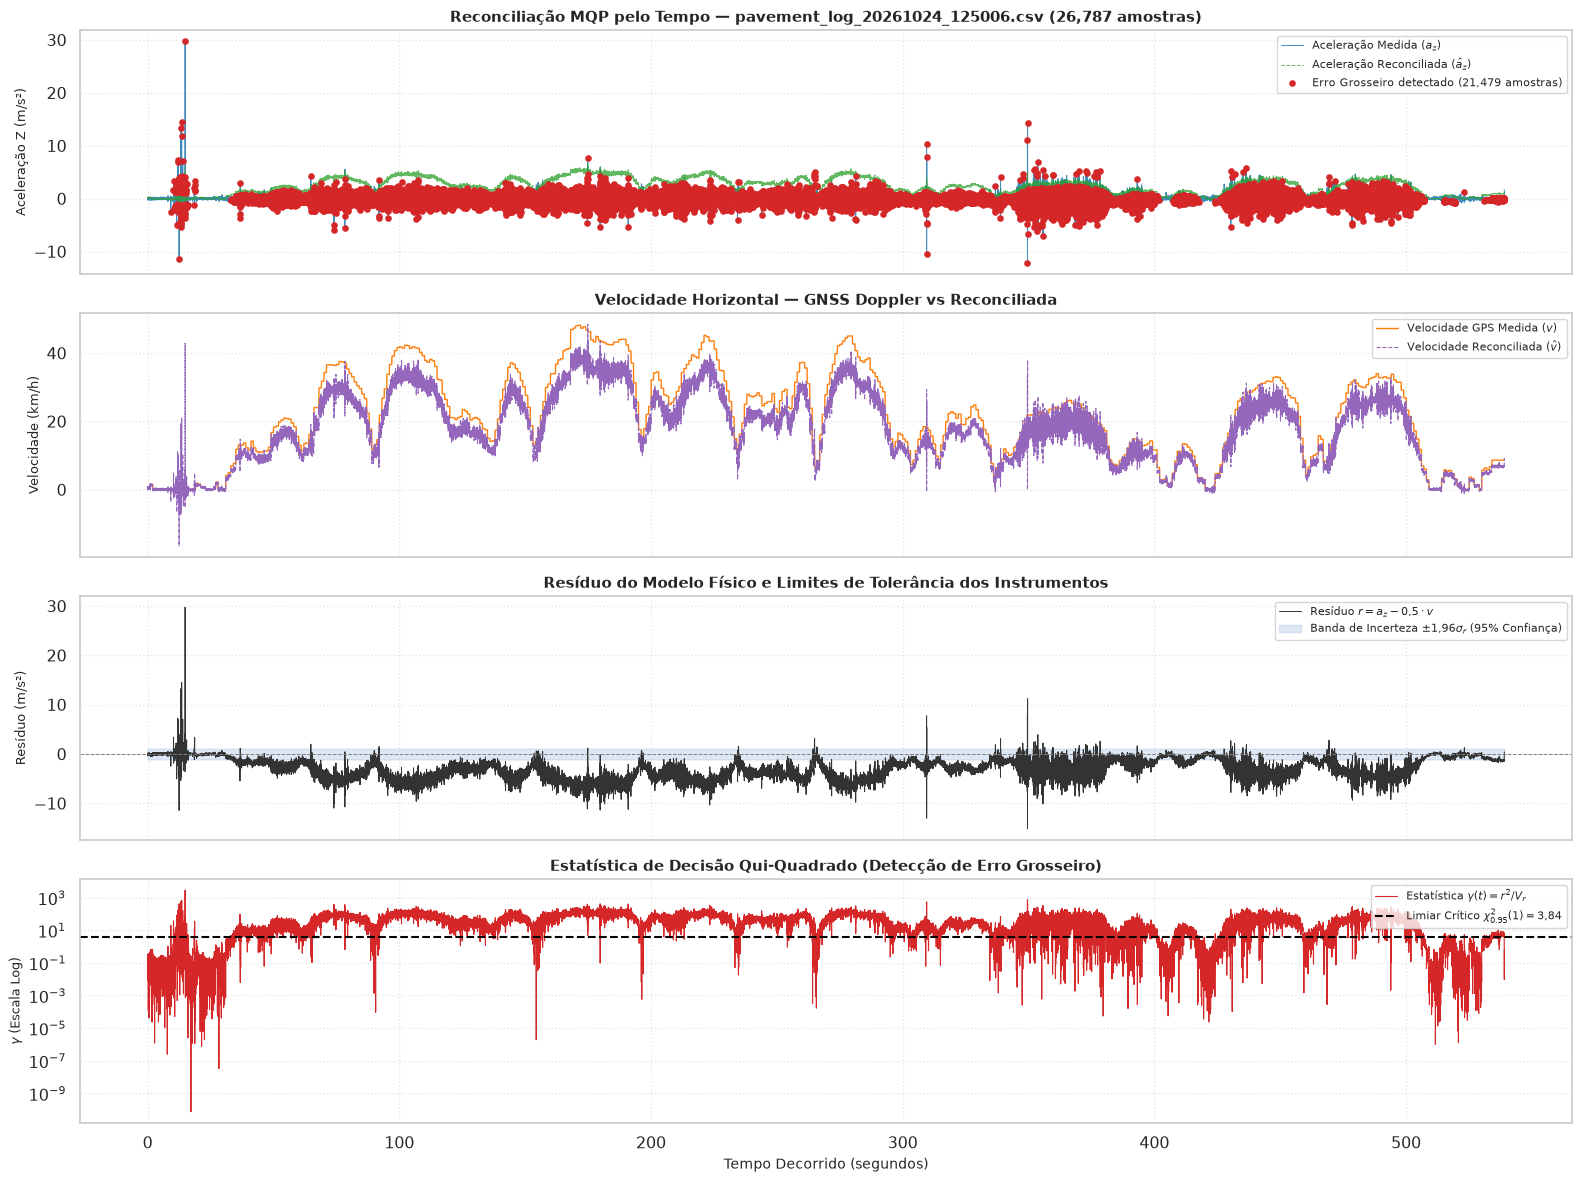

In [8]:
# ==============================================================================
# RECONCILIAÇÃO MQP NO LOG SELECIONADO
# Altere o número abaixo se desejar analisar outro log (ou mantenha NUMERO_LOG):
# ==============================================================================
LOG_MQP = NUMERO_LOG  # <--- DIGITE O NÚMERO DO LOG (1 a 11) E RODE O BLOCO!
# ==============================================================================

if 1 <= LOG_MQP <= len(active_logs):
    idx_mqp = LOG_MQP - 1
else:
    idx_mqp = max(0, min(int(LOG_MQP), len(active_logs) - 1))

target_entry = active_logs.iloc[idx_mqp]
print(f"==============================================================================")
print(f"🔬 EXECUTANDO RECONCILIAÇÃO MQP NO LOG [Nº {idx_mqp + 1}]: {target_entry['Arquivo']}")
print(f"==============================================================================")

df_selected = load_log(target_entry["Path"])
df_mqp = reconcile_series(df_selected, k=0.5, chi_threshold=3.84)

# ==============================================================================
# GRÁFICO MULTIVARIÁVEL TEMPORAL DO MQP (4 PAINÉIS SINCRONIZADOS)
# ==============================================================================
fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=True)

# 1. Aceleração Vertical Medida vs Reconciliada
axes[0].plot(df_mqp['elapsed_sec'], df_mqp['y_az'], color='#1f77b4', linewidth=0.7, label=r'Aceleração Medida ($a_z$)', alpha=0.85)
axes[0].plot(df_mqp['elapsed_sec'], df_mqp['reconciled_az'], color='#2ca02c', linewidth=0.7, linestyle='--', label=r'Aceleração Reconciliada ($\hat{a}_z$)', alpha=0.75)
anom = df_mqp[df_mqp['is_gross_error']]
if not anom.empty:
    axes[0].scatter(anom['elapsed_sec'], anom['y_az'], color='#d62728', s=14, label=f'Erro Grosseiro detectado ({len(anom):,} amostras)', zorder=5)
axes[0].set_ylabel('Aceleração Z (m/s²)', fontsize=9)
axes[0].set_title(f"Reconciliação MQP pelo Tempo — [Nº {idx_mqp + 1}] {target_entry['Arquivo']} ({len(df_mqp):,} amostras)", fontsize=11, fontweight='bold')
axes[0].grid(True, linestyle=':', alpha=0.5)
axes[0].legend(loc='upper right', fontsize=8)

# 2. Velocidade Horizontal Medida vs Reconciliada
axes[1].plot(df_mqp['elapsed_sec'], df_mqp['speed_kmh'], color='#ff7f0e', linewidth=1.0, label=r'Velocidade GPS Medida ($v$)')
axes[1].plot(df_mqp['elapsed_sec'], df_mqp['reconciled_speed_kmh'], color='#9467bd', linewidth=0.8, linestyle='--', label=r'Velocidade Reconciliada ($\hat{v}$)')
axes[1].set_ylabel('Velocidade (km/h)', fontsize=9)
axes[1].set_title('Velocidade Horizontal — GNSS Doppler vs Reconciliada', fontsize=11, fontweight='bold')
axes[1].grid(True, linestyle=':', alpha=0.5)
axes[1].legend(loc='upper right', fontsize=8)

# 3. Resíduo Linear do Modelo Físico e Faixa de Confiança
sigma_r = np.sqrt(df_mqp['var_r'])
axes[2].plot(df_mqp['elapsed_sec'], df_mqp['r'], color='#333333', linewidth=0.7, label=r'Resíduo $r = a_z - 0{,}5 \cdot v$')
axes[2].fill_between(df_mqp['elapsed_sec'], -1.96 * sigma_r, 1.96 * sigma_r, color='#aec7e8', alpha=0.4, label=r'Banda de Incerteza $\pm 1{,}96\sigma_r$ (95% Confiança)')
axes[2].axhline(0, color='gray', linestyle='--', linewidth=0.7)
axes[2].set_ylabel('Resíduo (m/s²)', fontsize=9)
axes[2].set_title('Resíduo do Modelo Físico e Limites de Tolerância dos Instrumentos', fontsize=11, fontweight='bold')
axes[2].grid(True, linestyle=':', alpha=0.5)
axes[2].legend(loc='upper right', fontsize=8)

# 4. Estatística Qui-Quadrado (Disparo de Anomalias)
axes[3].plot(df_mqp['elapsed_sec'], df_mqp['gamma'], color='#d62728', linewidth=0.8, label=r'Estatística $\gamma(t) = r^2 / V_r$')
axes[3].axhline(3.84, color='black', linestyle='--', linewidth=1.5, label=r'Limiar Crítico $\chi^2_{0.95}(1) = 3{,}84$')
axes[3].set_yscale('log')
axes[3].set_ylabel(r'$\gamma$ (Escala Log)', fontsize=9)
axes[3].set_xlabel('Tempo Decorrido (segundos)', fontsize=10)
axes[3].set_title('Estatística de Decisão Qui-Quadrado (Detecção de Erro Grosseiro)', fontsize=11, fontweight='bold')
axes[3].grid(True, linestyle=':', alpha=0.5)
axes[3].legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()


### 6.2. Zoom Temporal de Alta Resolução no Impacto do Buraco (+29,76 m/s²)

Para observar o funcionamento do detector no milissegundo exato da colisão mecânica com o buraco, recortamos uma janela temporal de 10 segundos ao redor do pico crítico registrado:

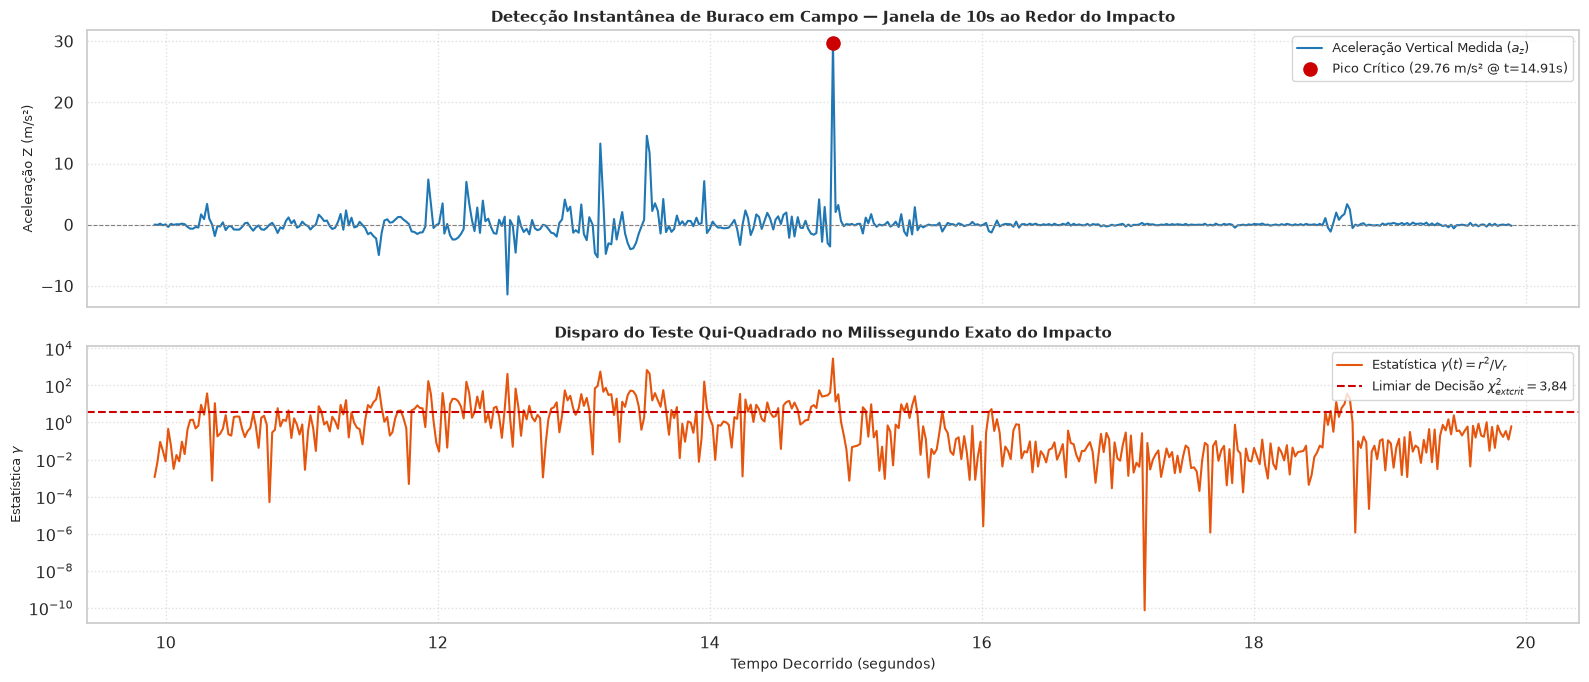

RELATÓRIO DE RECONCILIAÇÃO MQP E DETECÇÃO DE FALHAS — pavement_log_20261024_125006.csv
• Total de Amostras Processadas:              26,787
• Amostras com Erro Grosseiro (γ > 3.84):     21,479 (80.18%)
• Aceleração Z Máxima Registrada:             29.76 m/s²
• Resíduo Físico Máximo do Modelo:            29.76 m/s²
• Estatística Qui-Quadrado Máxima (γ):        2833.86 (Limiar = 3.84)
• Resíduo Pós-MQP (Desvio Máximo de Máquina): 1.78e-15 m/s²


In [9]:
# Localizar instante do pico máximo
idx_peak = df_mqp['y_az'].idxmax()
t_peak = df_mqp.loc[idx_peak, 'elapsed_sec']

# Recorte de 10 segundos centrado no evento
window_zoom = df_mqp[(df_mqp['elapsed_sec'] >= t_peak - 5) & (df_mqp['elapsed_sec'] <= t_peak + 5)].copy()

fig, (ax_z_zoom, ax_g_zoom) = plt.subplots(2, 1, figsize=(16, 7), sharex=True)

# Painel Superior: Aceleração Z com Destaque do Pico
ax_z_zoom.plot(window_zoom['elapsed_sec'], window_zoom['y_az'], color='#1f77b4', linewidth=1.5, label=r'Aceleração Vertical Medida ($a_z$)')
ax_z_zoom.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax_z_zoom.scatter([t_peak], [df_mqp.loc[idx_peak, 'y_az']], color='#cc0000', s=90, zorder=5, 
                  label=f"Pico Máximo ({df_mqp.loc[idx_peak, 'y_az']:.2f} m/s² @ t={t_peak:.2f}s)")
ax_z_zoom.set_title(f"Detecção Instantânea no Log [Nº {idx_mqp + 1} - {target_entry['Arquivo']}] — Janela de 10s ao Redor do Maior Pico", fontsize=11, fontweight='bold')
ax_z_zoom.set_ylabel("Aceleração Z (m/s²)", fontsize=9)
ax_z_zoom.grid(True, linestyle=':', alpha=0.6)
ax_z_zoom.legend(loc="upper right", fontsize=9)

# Painel Inferior: Estatística Qui-Quadrado no Instante do Impacto
ax_g_zoom.plot(window_zoom['elapsed_sec'], window_zoom['gamma'], color='#e6550d', linewidth=1.5, label=r'Estatística $\gamma(t) = r^2 / V_r$')
ax_g_zoom.axhline(3.84, color='#cc0000', linestyle='--', linewidth=1.5, label=r'Limiar de Decisão $\chi^2_{\text{crit}} = 3{,}84$')
ax_g_zoom.set_yscale("log")
ax_g_zoom.set_title("Disparo do Teste Qui-Quadrado no Instante do Impacto", fontsize=11, fontweight='bold')
ax_g_zoom.set_xlabel("Tempo Decorrido (segundos)", fontsize=10)
ax_g_zoom.set_ylabel(r"Estatística $\gamma$", fontsize=9)
ax_g_zoom.grid(True, linestyle=':', alpha=0.6)
ax_g_zoom.legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.show()

# ==============================================================================
# RELATÓRIO ESTATÍSTICO EXECUTIVO DO MQP
# ==============================================================================
print("=" * 70)
print(f"RELATÓRIO DE RECONCILIAÇÃO MQP E DETECÇÃO DE FALHAS — Log Nº {idx_mqp + 1}: {target_entry['Arquivo']}")
print("=" * 70)
print(f"• Total de Amostras Processadas:              {len(df_mqp):,}")
print(f"• Amostras com Erro Grosseiro (γ > 3.84):     {len(anom):,} ({len(anom)/len(df_mqp)*100:.2f}%)")
print(f"• Aceleração Z Máxima Registrada:             {df_mqp['y_az'].max():.2f} m/s²")
print(f"• Resíduo Físico Máximo do Modelo:            {df_mqp['r'].abs().max():.2f} m/s²")
print(f"• Estatística Qui-Quadrado Máxima (γ):        {df_mqp['gamma'].max():.2f} (Limiar = 3.84)")
print(f"• Resíduo Pós-MQP (Desvio Máximo de Máquina): {np.abs(df_mqp['post_residual']).max():.2e} m/s²")
print("=" * 70)


---
## 7. Análise Rápida de Qualquer Log em Um Único Bloco

Basta digitar o número do log desejado na variável `LOG_ESCOLHIDO` abaixo e executar este bloco (`Shift + Enter`).  
Ele processa a telemetria, roda o MQP, plota os gráficos e gera o relatório completo para aquele log de uma só vez:


In [ ]:
# ==============================================================================
# PAINEL RÁPIDO: DIGITE O NÚMERO DO LOG (1 a 11) E EXECUTE ESTE BLOCO:
# ==============================================================================
LOG_ESCOLHIDO = 2  # <--- DIGITE AQUI O NÚMERO DO LOG DESEJADO!
# ==============================================================================

def analisar_log_completo(numero_do_log: int):
    if 1 <= numero_do_log <= len(active_logs):
        target_idx = numero_do_log - 1
    else:
        target_idx = max(0, min(int(numero_do_log), len(active_logs) - 1))
        
    t = active_logs.iloc[target_idx]
    df_raw = load_log(t["Path"])
    df_proc = reconcile_series(df_raw, k=0.5, chi_threshold=3.84)
    anomalias = df_proc[df_proc["is_gross_error"]]
    
    print("=" * 75)
    print(f"🔍 ANÁLISE COMPLETA DO LOG Nº {target_idx + 1}: {t['Arquivo']}")
    print("=" * 75)
    print(f"• Volume de Dados:   {len(df_proc):,} amostras em {t['Duração']} ({t['Freq (Hz)']} Hz)")
    print(f"• Aceleração Z:      Média = {t['Z Médio (m/s²)']} m/s² | Máx = {t['Z Máx']} m/s² | DesvPad = {t['Z DesvPad']} m/s²")
    print(f"• Cinemática GPS:    {t['GPS Válidos']:,} pontos válidos | Vel Média = {t['Vel Média (km/h)']} km/h | Vel Máx = {t['Vel Máx (km/h)']} km/h")
    print(f"• Erros Grosseiros:  {len(anomalias):,} amostras detectadas ({len(anomalias)/len(df_proc)*100:.2f}%) com γ > 3.84")
    print("=" * 75)
    
    # Gráficos combinados
    fig, axes = plt.subplots(3, 1, figsize=(16, 9), sharex=True)
    
    # 1. Aceleração Z e Anomalias
    axes[0].plot(df_proc['elapsed_sec'], df_proc['y_az'], color='#1f77b4', linewidth=0.7, label='Aceleração Medida (az)')
    axes[0].plot(df_proc['elapsed_sec'], df_proc['reconciled_az'], color='#2ca02c', linewidth=0.7, linestyle='--', label='Reconciliada (MQP)')
    if not anomalias.empty:
        axes[0].scatter(anomalias['elapsed_sec'], anomalias['y_az'], color='#d62728', s=16, label=f'Anomalia / Erro Grosseiro ({len(anomalias)})', zorder=5)
    axes[0].set_ylabel('Z (m/s²)')
    axes[0].set_title(f"Aceleração Vertical e Reconciliação — Log Nº {target_idx + 1} ({t['Arquivo']})", fontweight='bold')
    axes[0].grid(True, linestyle=':', alpha=0.5)
    axes[0].legend(loc='upper right', fontsize=8)
    
    # 2. Velocidade
    if t["GPS Válidos"] > 0 and "speed_kmh" in df_proc.columns and df_proc["speed_kmh"].notna().any():
        axes[1].plot(df_proc['elapsed_sec'], df_proc['speed_kmh'], color='#ff7f0e', linewidth=1.1, label='Velocidade GPS')
    axes[1].set_ylabel('Velocidade (km/h)')
    axes[1].set_title('Velocidade do Veículo', fontweight='bold')
    axes[1].grid(True, linestyle=':', alpha=0.5)
    axes[1].legend(loc='upper right', fontsize=8)
    
    # 3. Estatística Qui-Quadrado
    axes[2].plot(df_proc['elapsed_sec'], df_proc['gamma'], color='#d62728', linewidth=0.8, label=r'Estatística $\gamma = r^2 / V_r$')
    axes[2].axhline(3.84, color='black', linestyle='--', linewidth=1.5, label='Limiar Qui-Quadrado (3.84)')
    axes[2].set_yscale('log')
    axes[2].set_xlabel('Tempo Decorrido (segundos)')
    axes[2].set_ylabel(r'$\gamma$ (Log)')
    axes[2].set_title('Decisão Qui-Quadrado (Detecção de Falhas e Buracos)', fontweight='bold')
    axes[2].grid(True, linestyle=':', alpha=0.5)
    axes[2].legend(loc='upper right', fontsize=8)
    
    plt.tight_layout()
    plt.show()

analisar_log_completo(LOG_ESCOLHIDO)
